# Network design, version 1: risk-based QKD placement

*Builds on `3b_network_design.ipynb` (version 0). Same Chattanooga-area grid, same physical limits.*

**What changed from version 0**
- **Value is measured as risk reduced, not voltage tier.** A substation is worth: MW at stake × chance its traffic is tapped (from the length of its route) × chance the BB84 alarm catches the tap (from `3a_bb84_grid_link.ipynb`) × (1 − q) for each trusted node its key passes through. The link between control centers carries data about the whole system, so it counts as the whole system's load (`cc_weight`).
- **An exact optimizer chooses the links.** This is an integer program, solved with SciPy's HiGHS solver. It finds the best total value within budget, so more budget can never mean less protection, which version 0 violated twice.
- **Budget is counted in QKD links,** with a trusted node counted as 0.2 of a link (it needs physical hardening but no QKD hardware). This is a weighting, not a price: QKD vendors do not publish prices.
- **Every method is scored the same way:** the optimizer, a greedy method (best value per unit of budget), the version 0 rule, busiest links first, and random links.
- **Robustness (SMAA):** uncertain values are given ranges, not single guesses. The optimizer runs 400 times with values drawn from those ranges, and the notebook reports how often each link is chosen.

All values and ranges are in `network_design/v1_model.py` (`DEFAULTS`, `RANGES`).

In [6]:
import importlib.util, subprocess, sys, json, os
for pkg in ("networkx", "scipy"):
    if importlib.util.find_spec(pkg) is None:
        %pip install -q {pkg}
from IPython.display import Image, display
D = "network_design"
for f in ("v1_model.py", "v1_run.py", "chatt_raw.json"):
    if not os.path.exists(os.path.join(D, f)):
        raise FileNotFoundError(f"Missing {D}/{f}: put the network_design/ folder next to this notebook.")
sys.path.insert(0, D)
import v1_model
hide = ("C_qkd", "C_tn")   # internal cost weights; only their ratio matters (a trusted node = 0.2 of a link)
print("Defaults:", {k: v for k, v in v1_model.DEFAULTS.items() if k not in hide})
print("Ranges tested:", {k: v for k, v in v1_model.RANGES.items() if k not in hide})

Defaults: {'db_per_km': 0.35, 'max_loss_db': 10.0, 'max_hops': 3, 'lam': 0.01, 'D': 0.95, 'q': 0.05, 'cc_weight': 1.0, 'beta': 1.0, 'gamma': 1.0}
Ranges tested: {'lam': (0.002, 0.03), 'D': (0.5, 0.98), 'q': (0.01, 0.1), 'cc_weight': (0.25, 1.0)}


In [7]:
# Run version 1 (about 1 minute): budget sweep for every method, the design at a budget of 8 links, and 400 SMAA draws
subprocess.run([sys.executable, f"{D}/v1_run.py", f"{D}/chatt_raw.json", D, "1200000"], check=True, capture_output=True)
s = json.load(open(f"{D}/v1_summary.json"))
d = s["design"]
u = s["parameters"]["C_qkd"]
print(f"Design at a budget of {s['design_budget']/u:.0f} links: {len(d['links'])} QKD links + {len(d['trusted_nodes'])} trusted nodes = {d['cost']/u:.1f} link-equivalents")
print(f"  risk reduced: {d['value']} = {100*d['share_of_max_value']:.0f}% of the most achievable ({s['max_value']})")
print(f"  load behind full-QKD paths: {d['mw_behind_qkd']} MW;  trusted nodes: {', '.join(d['trusted_nodes'])}")
print(f"  control centers joined by QKD: {d['control_centers_linked']}")
for sub, path in d["protected"].items(): print(f"    {sub}: {path}")
print(f"\nLargest shortfall vs. optimal at any budget: greedy {100*s['max_gap_vs_optimal']['greedy']:.1f}%, "
      f"version 0 rule {100*s['max_gap_vs_optimal']['v0_rule']:.0f}%")

Design at a budget of 8 links: 7 QKD links + 4 trusted nodes = 7.8 link-equivalents
  risk reduced: 218.48 = 83% of the most achievable (263.52)
  load behind full-QKD paths: 253.9 MW;  trusted nodes: CHATTANOOGA 12, CHATTANOOGA 24, ROSSVILLE 1, ROSSVILLE 2
  control centers joined by QKD: True
    RINGGOLD 5: CHATTANOOGA 3 > ROSSVILLE 2 > ROSSVILLE 1 > RINGGOLD 5
    ROSSVILLE 1: CHATTANOOGA 3 > ROSSVILLE 2 > ROSSVILLE 1
    ROSSVILLE 2: CHATTANOOGA 3 > ROSSVILLE 2
    CHATTANOOGA 13: CHATTANOOGA 3 > CHATTANOOGA 13
    CHATTANOOGA 11: CHATTANOOGA 3 > CHATTANOOGA 24 > CHATTANOOGA 12 > CHATTANOOGA 11
    CHATTANOOGA 12: CHATTANOOGA 11 > CHATTANOOGA 12

Largest shortfall vs. optimal at any budget: greedy 0.5%, version 0 rule 36%


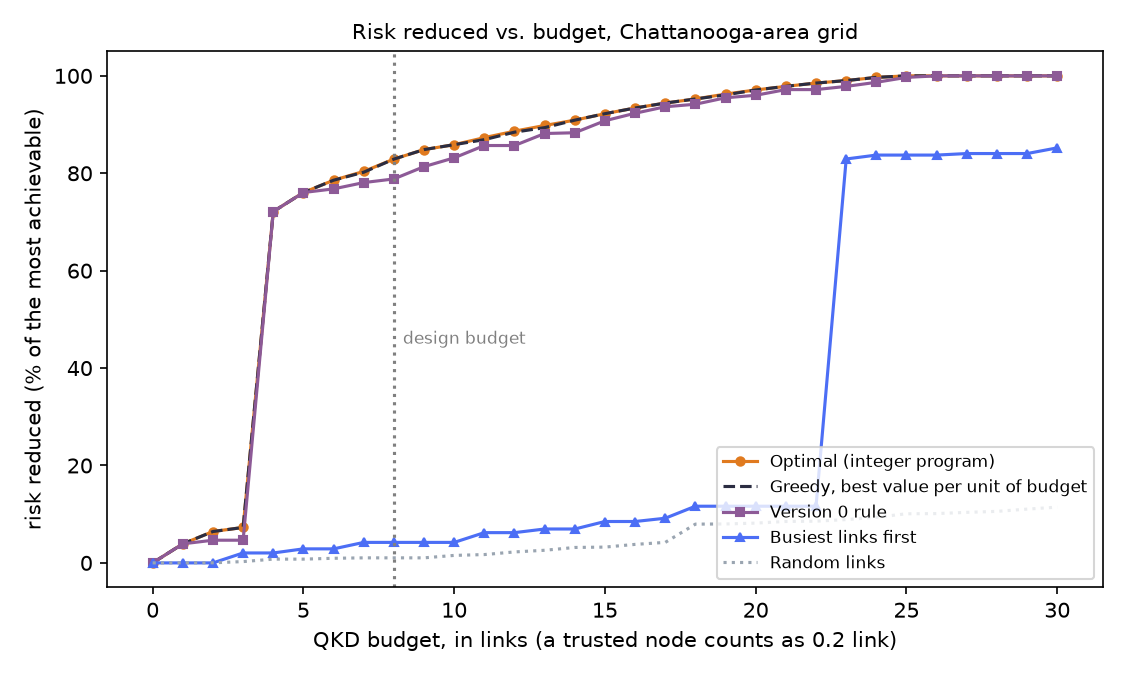

In [8]:
display(Image(f"{D}/v1_budget_curves.png"))

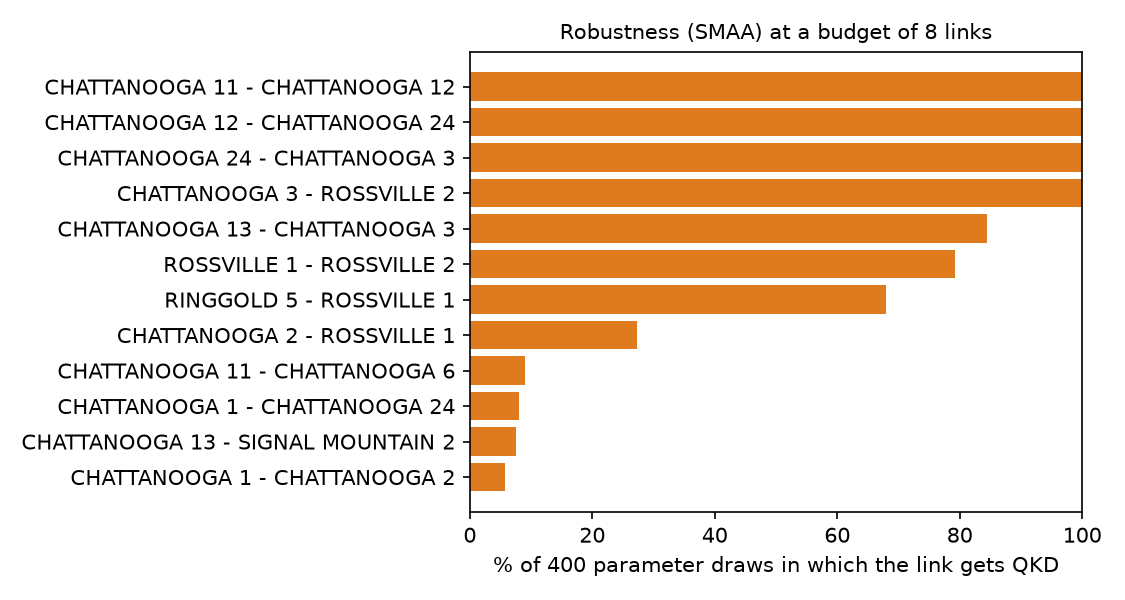

Share of 400 parameter draws in which each link gets QKD:
  100.0%  CHATTANOOGA 11 - CHATTANOOGA 12
  100.0%  CHATTANOOGA 12 - CHATTANOOGA 24
  100.0%  CHATTANOOGA 24 - CHATTANOOGA 3
  100.0%  CHATTANOOGA 3 - ROSSVILLE 2
   84.5%  CHATTANOOGA 13 - CHATTANOOGA 3
   79.2%  ROSSVILLE 1 - ROSSVILLE 2
   68.0%  RINGGOLD 5 - ROSSVILLE 1
   27.3%  CHATTANOOGA 2 - ROSSVILLE 1
    9.0%  CHATTANOOGA 11 - CHATTANOOGA 6
    8.0%  CHATTANOOGA 1 - CHATTANOOGA 24
    7.5%  CHATTANOOGA 13 - SIGNAL MOUNTAIN 2
    5.8%  CHATTANOOGA 1 - CHATTANOOGA 2
    4.5%  CHATTANOOGA 11 - CHATTANOOGA 27
    4.5%  CHATTANOOGA 21 - CHATTANOOGA 23
    4.5%  CHATTANOOGA 21 - CHATTANOOGA 27
    1.0%  CHATTANOOGA 20 - CHATTANOOGA 27
    1.0%  CHATTANOOGA 20 - RINGGOLD 5


In [9]:
display(Image(f"{D}/v1_smaa.png"))
print("Share of 400 parameter draws in which each link gets QKD:")
for k, v in s["smaa_link_frequency"].items(): print(f"  {100*v:5.1f}%  {k}")

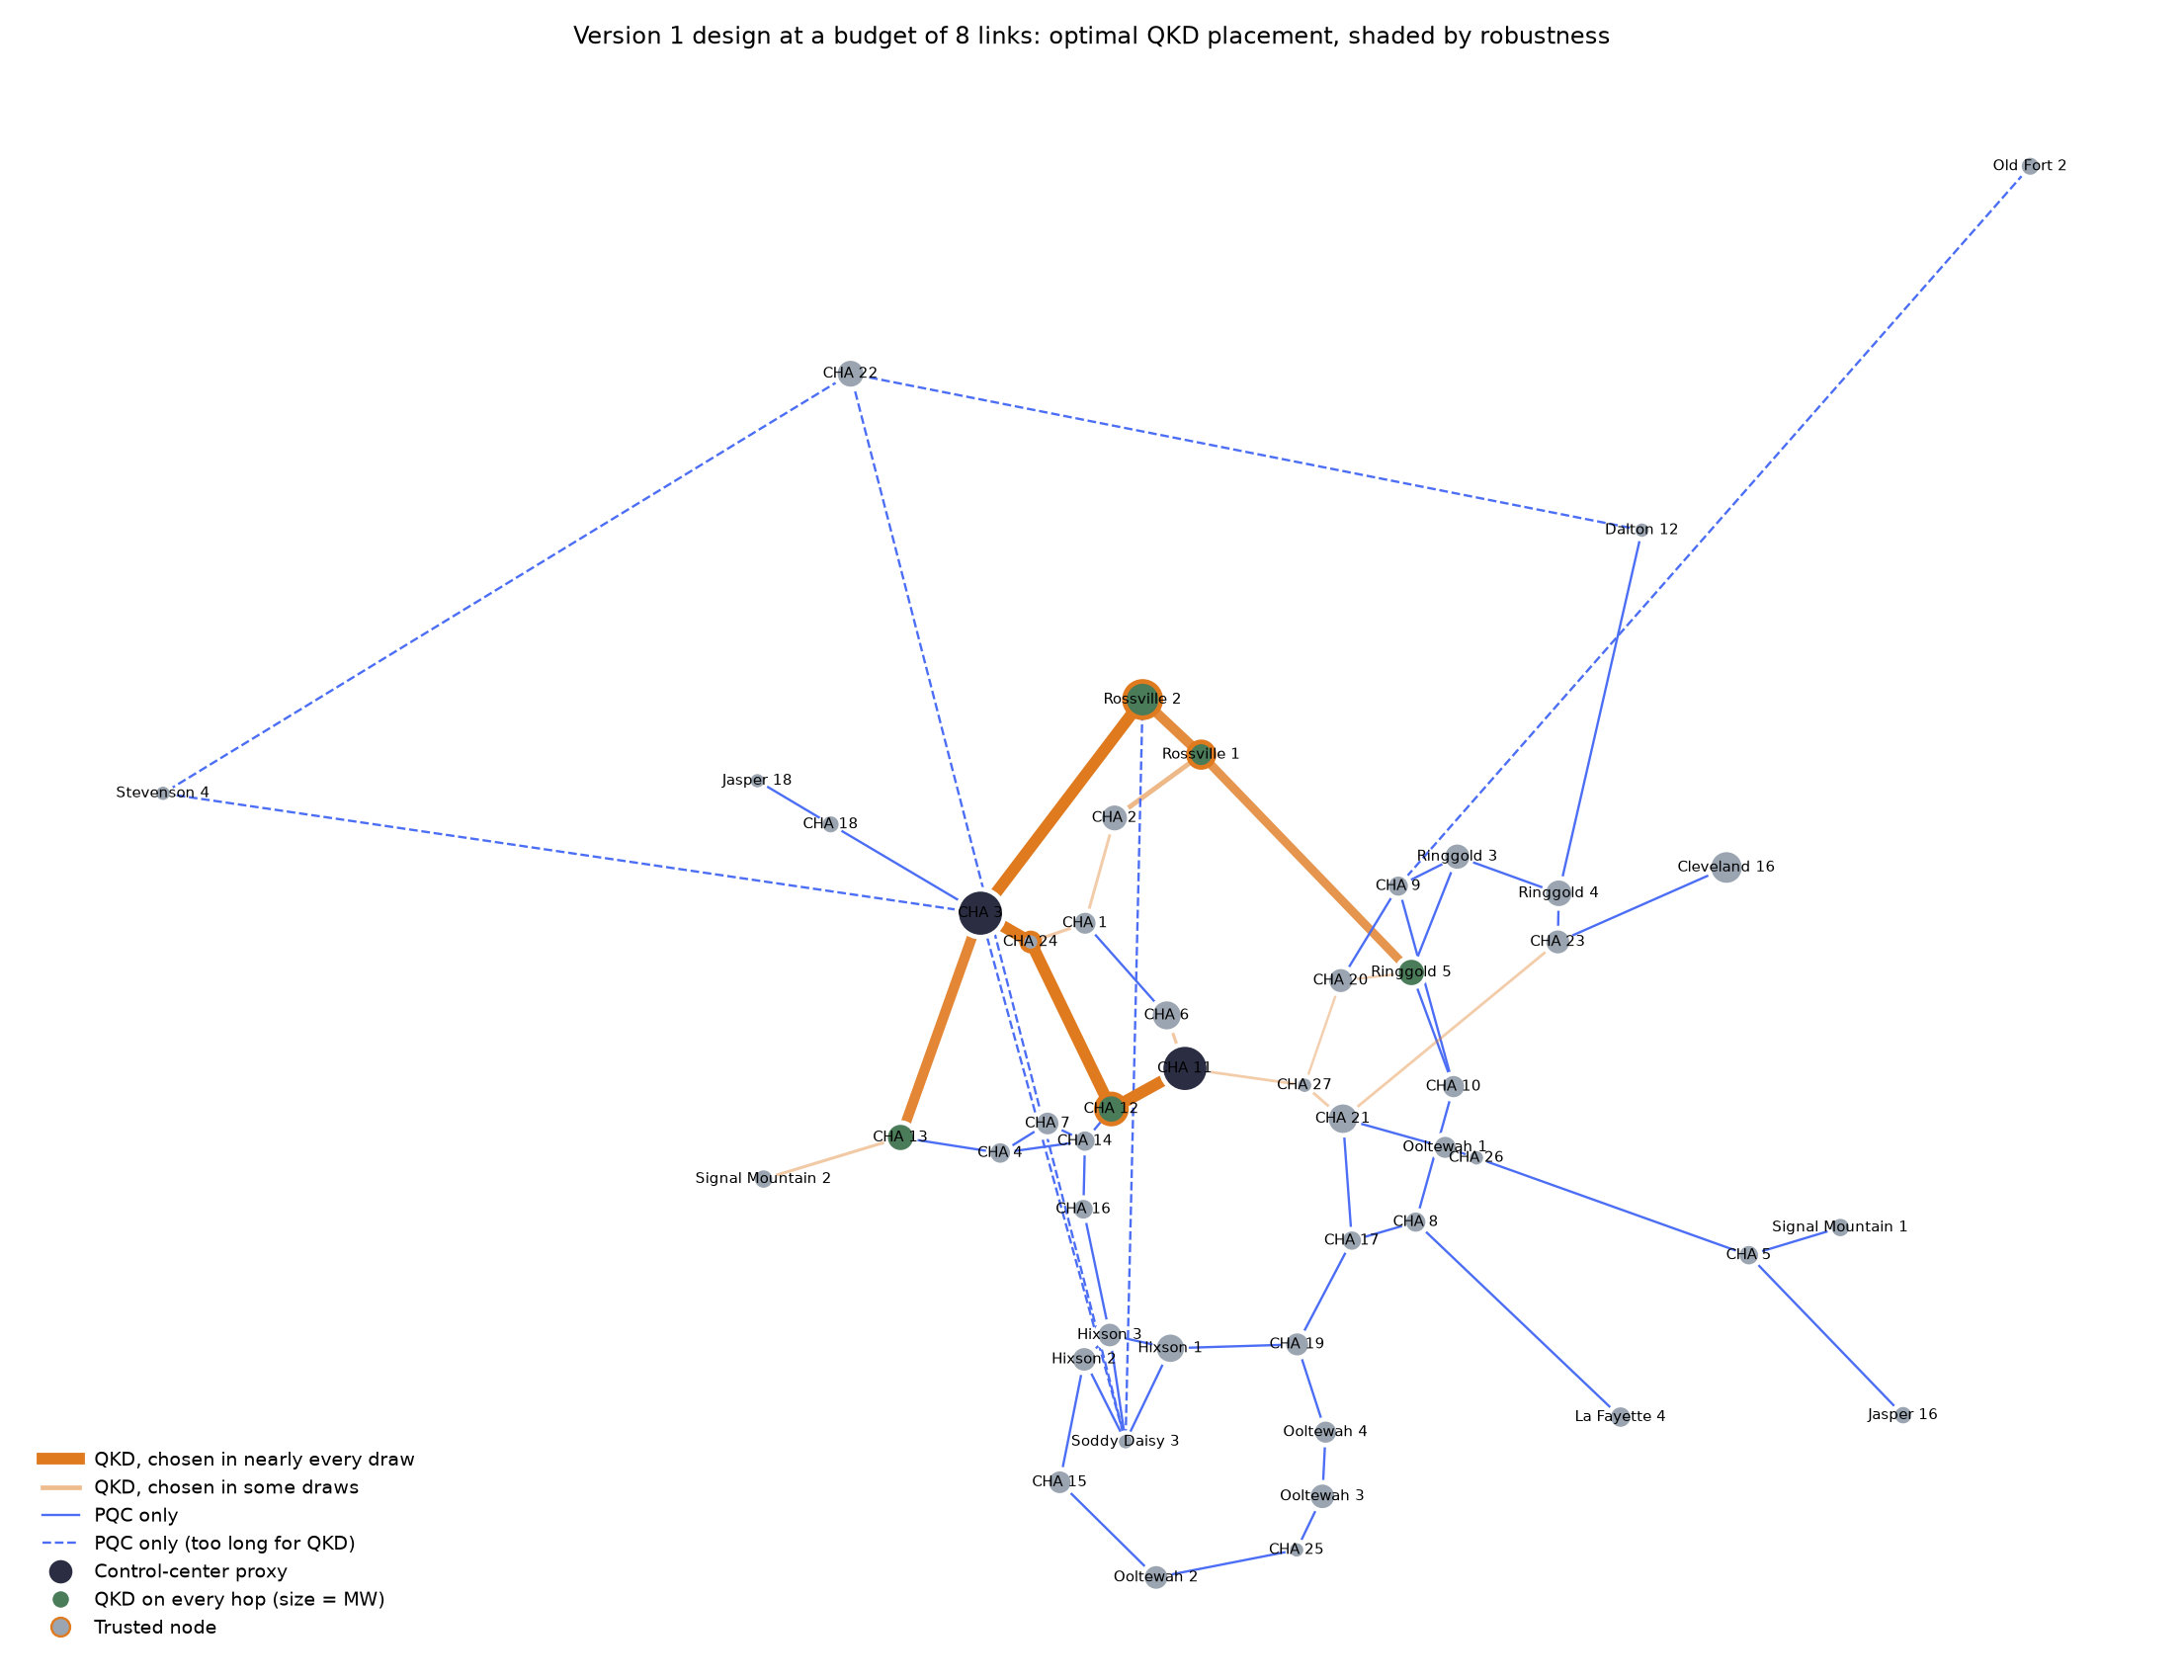

In [10]:
display(Image(f"{D}/v1_network_map.png"))

## What to look for
- **Budget curves:** the optimizer never drops as the budget grows. The jump near 4 links is the three-hop chain joining the control centers. After that, returns shrink.
- **Greedy vs. optimal:** if greedy stays within about 1%, the network is simple enough that a careful engineer gets close. The optimizer's job is then to *guarantee* that and to rule out failures like version 0's.
- **SMAA:** links chosen in nearly every draw don't depend on the uncertain values. Those are the safe first purchases.